# Лабораторная работа 2
## Разведочный анализ данных и метод максимального правдоподобия
**Вариант 9 · Дождиков Александр · группа 421702**

Цель — выполнить EDA реальных данных, оценить параметры нормальной модели численно и аналитически, сравнить ММП с методом моментов и проверить свойства оценок в 500 экспериментах Монте-Карло.

В методичке нет распределения заданий по вариантам. Номер 9 используется как seed. Выбран набор **Palmer Archipelago (Antarctica) penguin data**, файл `penguins_size.csv`.

- Страница Kaggle: https://www.kaggle.com/datasets/parulpandey/penguin-dataset-the-new-iris
- Использованный CSV из открытого зеркала: https://raw.githubusercontent.com/dickoa/penguins/master/data/penguins_size.csv
- Описание и происхождение: https://github.com/dickoa/penguins
- Первичная публикация: Gorman K. B., Williams T. D., Fraser W. R. (2014), https://doi.org/10.1371/journal.pone.0090081

Прямая загрузка с Kaggle в среде выполнения вернула HTTP 403; поэтому использован опубликованный CSV зеркала этого набора. Побайтовое равенство текущей версии Kaggle не проверялось. Данные реальны, не сгенерированы. Копия CSV включена в архив и встроена в notebook для автономного запуска. Отсутствие повторения набора внутри учебной группы нужно подтвердить отдельно.

**Запуск:** Python 3.11+ (проверено на Python 3.12), `pip install numpy pandas scipy matplotlib seaborn jupyter`. Открыть notebook в Jupyter / VS Code / Colab и выполнить все ячейки по порядку. Интернет для расчётов не нужен. Графики и таблицы сохраняются в `figures/` и `results/`.

In [1]:
from pathlib import Path
import io, base64, zlib, hashlib, math, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from scipy.optimize import minimize
SEED = 9
B = 500
OUT = Path('.')
(OUT / 'figures').mkdir(exist_ok=True)
(OUT / 'results').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=0.95)
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 140)

def savefig(name):
    plt.savefig(OUT / 'figures' / (name + '.png'), dpi=170, bbox_inches='tight')
    plt.show()
    plt.close()

def table(frame, name):
    frame.to_csv(OUT / 'results' / (name + '.csv'), encoding='utf-8-sig')
    display(frame.round(6))

print('Python', sys.version.split()[0])
print('NumPy', np.__version__, '| pandas', pd.__version__, '| SciPy', scipy.__version__)

Python 3.12.14
NumPy 2.3.5 | pandas 2.2.3 | SciPy 1.17.0


In [2]:
# Встроенная неизменённая копия исходного CSV, сжатая только для компактности.
CSV_B64 = 'eJyFW8uOHbkN3edbCo3SW1o6k8lsklllbzj2jaeBfsHtAZK/j8RDqeqWRDZgNOCBTFHk4eEhq+f97fb18fa+Pb4/fXn5tn398+n59vL56fby/ecfn5+f+3/4dnvD3//z9Pj2dvtxOvHv12//+/z85f398/ft/fbfv3z6dnt6vG3/ev3x/fbj/fayufJgNpMfUv1hNpfCvv3z0z9+XR4Mm0kPvh6Mm8v7vv391/VRvz+4emozJWzOBvng75/OfxZ3xuZXadaK25xXTLl2yu4PsR7d6z+U35EfSntHxoOjDZpN266P9BIfU5BsegTRsJ/14Oo53jYPLXnoW1yWbybXEhmscXa7fqwFur43Cce8aYZSe0K2NRlK1mpg4mYN+WeQYPG1dLC9Nm/eywdjuxehDvBRubxlGpDR8uxthWGNYjudtnpS8bJBlX74Gkclz56eU9FdfLV/sfjXx/evrzeOd27xTtWcn95ynEu9nhoOBWuhgZDglcuqmPq5TEcIDDUwJaytZWDB4s5r5o47G1jaxTkpd3oqokw/KpjD+s56iuiArc3AOuJR2FqqADRTau/swbt9funffty+PDMHESmkvKIWPpZG1Nqxssu2kNWMOlvZqn6V7pcXbcUGswT0zkgbF9peNrEW5vqFLZV2B4mtg1ArgF4XEKkgByEydzaek95XvWpETQir6L/y5nhfIELPyxSOSGUuuBYGKVLd9cptRoo50WmhGo8zwfT3NSQUFMYuv44uzODcazXydcgJXld5eXnZQGcqmy13BH+8jLDeMjcz2MidOzh2wkCvmQLeTAhTUCrVdGxWInZS3auOdVvU6Rq11jjtgl8eUTBU87aIfhlQb0QnSYJf1IYZCjOKL2yU0Volbosghkhgt1my1ovCENdPaudgyjO4ZM4yyKaBPrji9O7OBFtRiRnlsqXByhkA0XC1yu+s1iIUmJW7RkDMLNOWYst0hqgoM3LHpaYWuwTbtS5uwDqeJYSs1hz1ZRZ1moAo6LueqVP2kovLErksgHfyMoDRCrTGtVrvXh4YzGXXhU5lgMwU2DBjRZtoPJHiZD4QT3hNlzrK2ynbkQtYf7sdWW9+7roaZPFRdIVZbRYWo43Xr7xw1f1U9Gupchd605HkZvU26Ntxr2+xnKE+GgHNEA7scFU+oxc6UCXl+kpI41BXPS0oM4OPbu9OMlAQPSB47mGLIuBjRFpNPFhZFHSWqRy5h7ljsKVBMWEldO87K8aUqYJHGGwfUpKqsbjO7L7oYyMMpjeVZY0NW67XV/XLrf1yzVZkgbhoZGzLDaXVOPnKfFN/rYFPk/gbLNpknd0rRtNFYtxNDqy69yTYoTmEBeLEHrPmrjVhi+RT50zWtoLSd/kgzIKeKc8qQ7oKsYIohyQ10hsRd2bdlNbRykhhoA7ishj30IZV1LSZFeBdJCgBTWWI0wy0N4q/+mYF3wruTKAbWSdZxN8Bq7u8X8hdQizRetcJiMEC50q2SGyRwDszH14XCIPJnBUtcq1b1Posmu68pLVORu7kGd7TtqQ5Gj/YCrDiDKC/rL27WiSh0mSnqlGwTKJIav2Ph28Wu3YC9Z2Xoed7wb5njcIM3CyqPmLxVEXo/oGP5yFA3YU49FNLCJ9yM3h9iBintDeemoBG79NytMrHhiph/pI715BYwnQZQFUBkZsJZvQI2sQZmnZcWfuVmF4+6IKpB9bNfHy6jvPpZFvA2yggIVoky0hutq3FjI1hC+VNrVIaaV3Xl1aboPs2K8xb1dNiY3RmIQjYBY51nBdS4/rCcL0HHK7n07r1OsWdLbHSFdWC6Qi1uzlV0C9/PL68//zx5a2fiw/nLn8C/PVk2Ht/iCeUTqfMEH7tBSOu070BvAbqd+EojsmiPTg1nXK+sGh7iDMkp2DRxzGRXpZt69fkzhlJfE3s01TANKXaK3Qyn/YHCw8HXNzdmLCwmE7KfvTFyWLqcvV+Xz1Hu6toc5rVF7EeRN42dUnOHlo2yQbNYtipvyPOTkRXPn3gUF7h47Gnud8NTSe5xO1l0zGds9hP8NIxKnfnY2Q2IMX1OYeRNU47p0Vs4jEJHoPZ4tWDs8PdULLK8nX2X2eu8Rr1Eq+8GLSAc5p3/jSqqhjEJECTXBAxuI+lzGVPP9nz6IoZGBTRRV9gsISnoU6rY8ytNPUY0R5PIfjKdnwxmWsT92ZoWwUJHmqCdZbLiocWOp30k5aTsdiq/0DLCdZVNMmG09ep+c28bTXnNf/iXtt3pAldQsZ+6duaeJrkFowUoAviB10MzFVwMqrMlU8d1Ct1Ys57aK1OmAmNVVAYuHMzCq344jK+k7ZeorzE80TpgS+n9FqaNgq9WMkeRqz+8VrhwoBRkVqU0/qJBWe6jyuPvxGxGhCzAjUQx/CidgDXka35GPZ+MyYxsQLCwdZeVzbmoVfLHvVqyV2yF7VafB9+S9CrKmBL3d6SNHXo+ncRerPeA2Lvo07RIaiqAl4SmbPHOrFOOrD92+3l5+vr2DOQknP0+dGAlZbnmnZt203r9i0M1XWxRde1sZN8O2mG2VagG7Nsi3jaEw+G2n+EU5RSx2zpg3QjtDJ+N8GAzaVopOZb+3RTaqUIt7qGd0d9vUDxSNZys+bxhqETLqeITx11Gv7KurZWsJa0Jlb0CbYC4vGhrXzEw1VNKFrL/dSO/bngWYtHoFuTbM2eMmXkV2IJU9FhzRadmHfL6GgZkPOZkc8aNWtrB157hlrxlHUFkfQ1YSByV7Ie+jmno4OiltmeFDWgw3x8q+GXEtaEN3j45ghFxB6/f5orr6EWdqLgVT4ixt/OlUqvp6oWFTGbEAeHHFkxDoRFi4wnMQ5Hliovh13kIHzqIz6LUuwLbGX4L2OWqin2d0pcZduNqM2KiyJa831OAgcJvvlmK/JXEcWzxJVZz0n4x67Z8Skne0Yxq3fWhqxUieuv3KHRFFsBOExiXQYsZAkZEn4c4lqIfXxRkBH6OY3NzrcqncejLh0Y1Ci32lOVy3wWGd00bSj5DNxhG9Ika1wDnvuw8lJDObDMLAqb+Q+jy52u+SXVk2s17M7f8pRMBbYl9uDRAbKqNVo1gV281jcJtRnW5E7HfadQd1LinzrSvBZ/P/qmMzLXhsF8RmW+Ao2bdY3GL/CHQpg7QOm//WFtZaAsZiCwXzVPsl+YYFo2ndYD0h0bSNGnXEZEX0JGRsXxKakTMq4zNIuWcX94pugMMGOLvBSvNOLVOpjcMw1mTXSTKL2SeMUxrygx4ynOI/5F73QBk/XpF58vvllwI8fWi9kc6tLim7aiDgoqU+pNzLOZbSl1zrO8tbXTRRGzvqM/6zlwveayXOfIKDzL0oQVLL5rEzZk/IPxmldi/8Xknoj9s9yZwqE/tYj1KjeIv8Q+rBh5ohA7E+JPXGajPDkVVHBGPZX+JWKqucL4sVpk+xTjsXeQUWv67wNQp5MUVe45KNo7sbfXUZbAQNDQvoj+l95/q60g2uqdiRjIhgVf83aDtb9kyWA6Z2Um87U7clRkazQDe/TLoGSoTyW7bKsrLovZVp5xCjBW0JckLnOHNafMwNgSjp2G9E7ulwb6x4lVTpqrdwCtlvqcTLh+mAOWe+u1MvknkD8XZZGAf/l/aFaowQwX9Mr2vbKrChe0OvqMZ55W+ml5GHsMd+Kw/wPys/v6'
source_path = Path('data/penguins_size.csv')
raw_bytes = source_path.read_bytes() if source_path.exists() else zlib.decompress(base64.b64decode(CSV_B64))
print('SHA256:', hashlib.sha256(raw_bytes).hexdigest())
raw = pd.read_csv(io.BytesIO(raw_bytes))
print('Размер исходных данных:', raw.shape)
display(raw.head())
raw.info()
table(pd.DataFrame({'тип': raw.dtypes.astype(str), 'пропусков': raw.isna().sum(),
                    'уникальных': raw.nunique()}), 'structure')
print('Значения пола:', raw['sex'].unique())
print('Полных дубликатов:', raw.duplicated().sum())

SHA256: aa728597b2228a2637e39c6f08e40a80971f4cdac7faf7bc21ff4481ee3e3ae9
Размер исходных данных: (344, 7)


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


,тип,пропусков,уникальных
species,object,0,3
island,object,0,3
culmen_length_mm,float64,2,164
culmen_depth_mm,float64,2,80
flipper_length_mm,float64,2,55
body_mass_g,float64,2,94
sex,object,10,3


Значения пола: ['MALE' 'FEMALE' nan '.']
Полных дубликатов: 0


## 1 Первичная обработка
Количественные признаки: длина клюва `culmen_length_mm`, глубина клюва `culmen_depth_mm`, длина ласта `flipper_length_mm` (мм), масса `body_mass_g` (г). Вид, остров и пол — категории; числовое кодирование этих названий создало бы искусственный порядок, поэтому оно не используется в корреляциях и оценке нормального распределения.

Обозначение пола `.` заменяется пропуском. Удаляем строки без хотя бы одного из четырёх измерений: их мало, а заполнение медианой искусственно уменьшило бы дисперсию и исказило распределение. Строки только с неизвестным полом сохраняем для общего EDA, но не включаем в анализ самок. Это предполагает, что потеря двух измерительных записей не вносит существенного смещения; механизм пропусков по этим данным не доказан. Полные дубликаты удаляем, если они обнаружатся. Выбросы по IQR отмечаем, но автоматически не удаляем без свидетельства ошибки измерения.

In [3]:
features = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
labels = {'culmen_length_mm': 'Длина клюва, мм', 'culmen_depth_mm': 'Глубина клюва, мм',
          'flipper_length_mm': 'Длина ласта, мм', 'body_mass_g': 'Масса, г'}
df = raw.copy()
df['sex'] = df['sex'].replace('.', np.nan)
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')
print('Пропуски после нормализации пола:', df.isna().sum().to_dict())
removed_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates()
removed_missing = int(df[features].isna().any(axis=1).sum())
df = df.dropna(subset=features).copy()
for col in ['species', 'island', 'sex']:
    df[col] = df[col].astype('category')
print(f'Удалено дубликатов: {removed_duplicates}; строк без измерений: {removed_missing}')
print('Осталось:', len(df), '; неизвестный пол:', df['sex'].isna().sum())
assert np.isfinite(df[features].to_numpy()).all()
assert (df[features] > 0).all().all()
table(df.groupby('species', observed=True).size().to_frame('n'), 'species_counts')
df.to_csv(OUT / 'results/penguins_clean.csv', index=False, encoding='utf-8-sig')

Пропуски после нормализации пола: {'species': 0, 'island': 0, 'culmen_length_mm': 2, 'culmen_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 11}
Удалено дубликатов: 0; строк без измерений: 2
Осталось: 342 ; неизвестный пол: 9


,n
species,
Adelie,151
Chinstrap,68
Gentoo,123


## 2 Описательные статистики и распределения
Стандартное отклонение в описательной таблице рассчитано с делением на n−1. Асимметрия и эксцесс — исправленные выборочные оценки pandas; для нормального распределения теоретический эксцесс равен нулю. IQR = Q3−Q1; границы выбросов Q1−1,5·IQR и Q3+1,5·IQR.

,count,mean,std_ddof1,min,25%,median,75%,max,skew,excess
culmen_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6,0.053118,-0.876027
culmen_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5,-0.143465,-0.906866
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0,0.345682,-0.984273
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0,0.470329,-0.719222


,lower,upper,count
culmen_length_mm,25.3125,62.4125,0
culmen_depth_mm,10.9500,23.3500,0
flipper_length_mm,155.5000,247.5000,0
body_mass_g,1750.0000,6550.0000,0


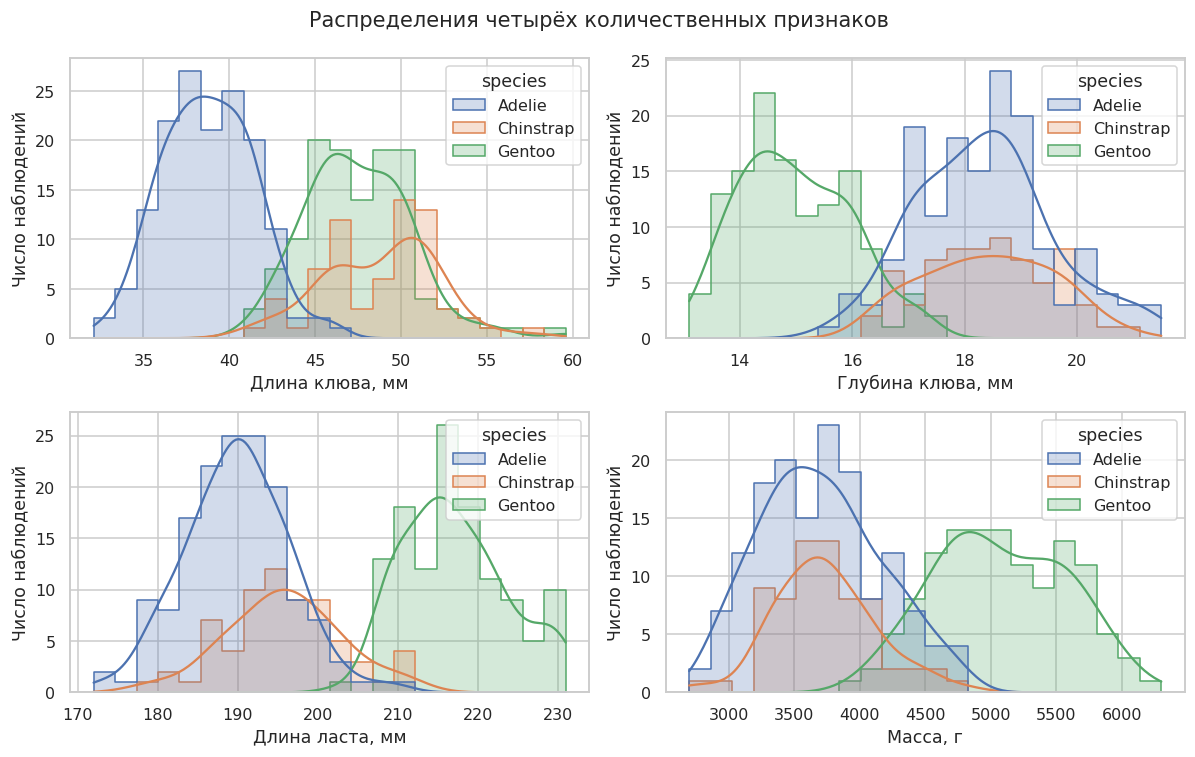

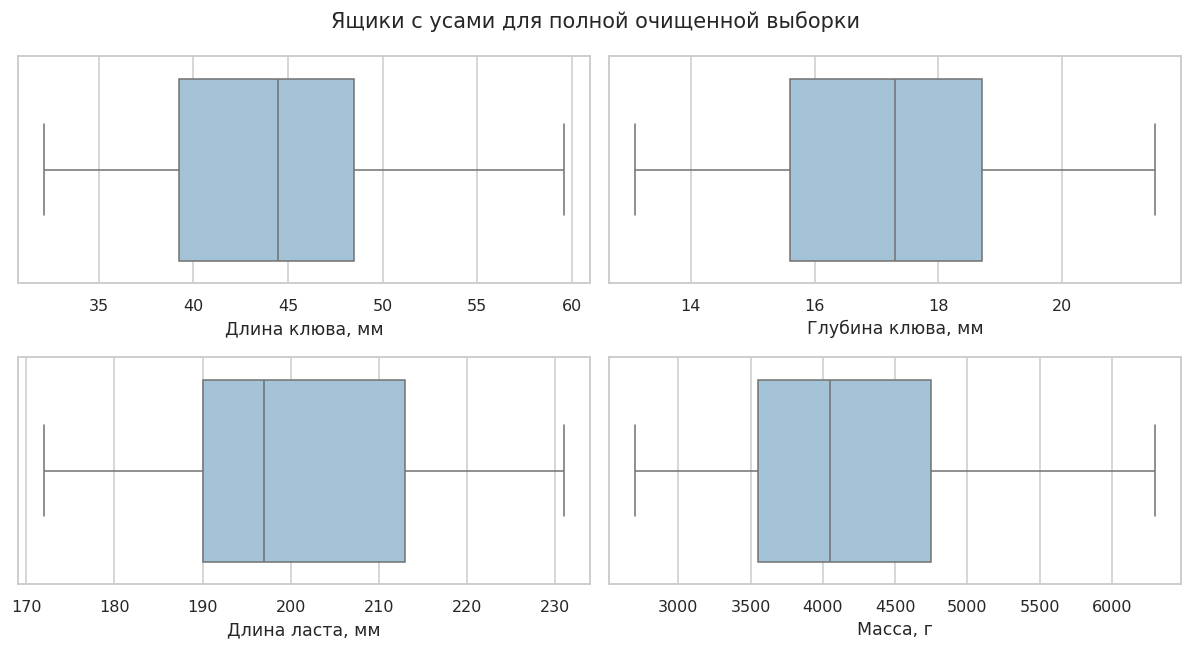

In [4]:
desc = df[features].describe().T
# Переименование делает смысл столбцов однозначным.
desc = desc.rename(columns={'50%': 'median', 'std': 'std_ddof1'})
desc['skew'] = df[features].skew()
desc['excess'] = df[features].kurt()
table(desc, 'descriptive')
q1, q3 = df[features].quantile(.25), df[features].quantile(.75)
iqr = q3-q1
outliers = pd.DataFrame({'lower': q1-1.5*iqr, 'upper': q3+1.5*iqr})
outliers['count'] = ((df[features] < outliers['lower']) | (df[features] > outliers['upper'])).sum()
table(outliers, 'outliers')
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, features):
    sns.histplot(data=df, x=col, hue='species', bins=22, kde=True,
                 element='step', stat='count', common_norm=False, ax=ax)
    ax.set(xlabel=labels[col], ylabel='Число наблюдений')
fig.suptitle('Распределения четырёх количественных признаков')
plt.tight_layout(); savefig('01_histograms')
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, col in zip(axes.flat, features):
    sns.boxplot(x=df[col], ax=ax, color='#9cc5df')
    ax.set(xlabel=labels[col])
fig.suptitle('Ящики с усами для полной очищенной выборки')
plt.tight_layout(); savefig('02_boxplots')

## 3 Корреляции и мультиколлинеарность
Рассчитываем корреляции Пирсона и VIF = diag(R⁻¹) для четырёх количественных признаков. VIF имеет смысл для совместного включения этих признаков в линейную модель с константой. Значения порядка 5 и выше — диагностический сигнал, а не универсальная граница. Диаграммы окрашены по видам, чтобы отделить межвидовые различия от зависимостей внутри групп.

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.000000,-0.235053,0.656181,0.595110
culmen_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


,VIF
culmen_length_mm,1.868456
culmen_depth_mm,1.621511
flipper_length_mm,5.930499
body_mass_g,4.192353


,corr_length_depth
species,
Adelie,0.391492
Chinstrap,0.653536
Gentoo,0.643384


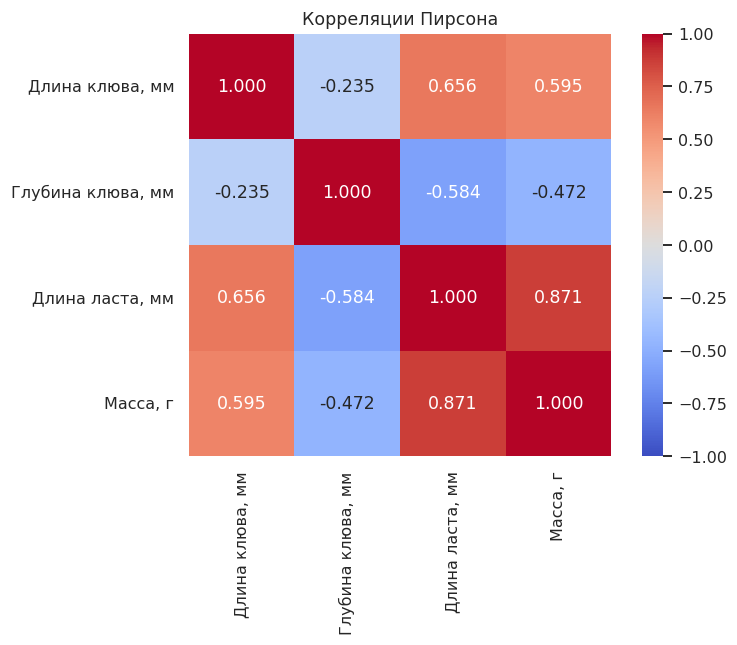

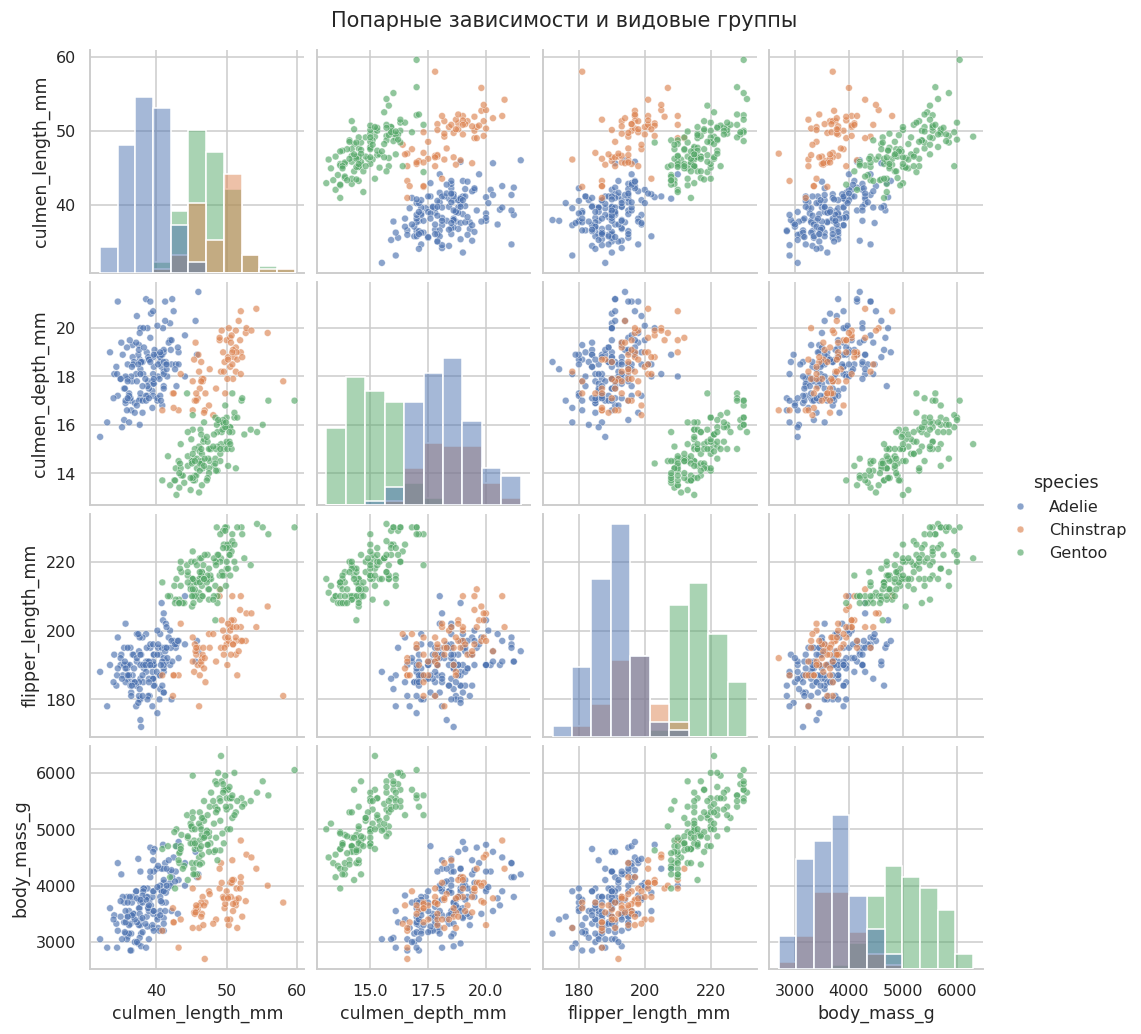

In [5]:
corr = df[features].corr()
table(corr, 'correlation')
vif = pd.DataFrame({'VIF': np.diag(np.linalg.inv(corr.to_numpy()))}, index=features)
table(vif, 'vif')
within = df.groupby('species', observed=True).apply(
    lambda g: g['culmen_length_mm'].corr(g['culmen_depth_mm']), include_groups=False)
table(within.to_frame('corr_length_depth'), 'within_species_correlation')
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr.rename(index=labels, columns=labels), annot=True, fmt='.3f',
            cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Корреляции Пирсона'); plt.tight_layout(); savefig('03_correlation')
g = sns.pairplot(df, vars=features, hue='species', diag_kind='hist',
                 plot_kws={'alpha': .65, 's': 20}, height=2.3)
g.fig.suptitle('Попарные зависимости и видовые группы', y=1.02)
savefig('04_pairplot')

## 4 Выбор признака и вывод ММП
Выбрана **длина клюва самок Adelie**. Ограничение по виду и полу биологически обосновано различиями размеров; оно не подбирается перебором p-значений. Анализируется условное распределение для этой группы, а не для всех пингвинов. Острова не разделяются: это ограничение модели.

Предполагаем независимые одинаково распределённые наблюдения $X_i\sim N(\mu,\sigma^2)$, $\sigma>0$.
$$L(\mu,\sigma)=\prod_{i=1}^n\frac1{\sqrt{2\pi}\sigma}\exp\left[-\frac{(x_i-\mu)^2}{2\sigma^2}\right].$$
$$\ell(\mu,\sigma)=-\frac n2\log(2\pi)-n\log\sigma-\frac1{2\sigma^2}\sum_i(x_i-\mu)^2.$$
Условия стационарности:
$$\frac{\partial\ell}{\partial\mu}=\frac{\sum_i(x_i-\mu)}{\sigma^2}=0,\quad
\frac{\partial\ell}{\partial\sigma}=-\frac n\sigma+\frac{\sum_i(x_i-\mu)^2}{\sigma^3}=0.$$
Отсюда $\hat\mu=\bar x$, $\hat\sigma^2=n^{-1}\sum_i(x_i-\bar x)^2$. Для непостоянной выборки это максимум. При фиксированном σ сумма квадратов минимальна в среднем; после подстановки среднего профильное правдоподобие максимально при указанной дисперсии.

Численная модель минимизирует **самостоятельно заданное** отрицательное логарифмическое правдоподобие методом L-BFGS-B. Начальная точка намеренно отличается от аналитического решения. Длина выборки берётся из аргумента функции, а не из глобальной переменной.

n = 73 | начальная точка = [38.0, 2.8404361413986714]
Оптимизация: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH | итераций: 10
ММП численно: [37.25753425  2.01493858] | log L = -154.72548901746768
Шапиро–Уилк: W=0.991170; p=0.895192; alpha=0.05
Асимметрия: 0.028445913715400596 Эксцесс: -0.2448531270774068
Разность с формулами: [ 5.46904744e-11 -3.47548657e-11]


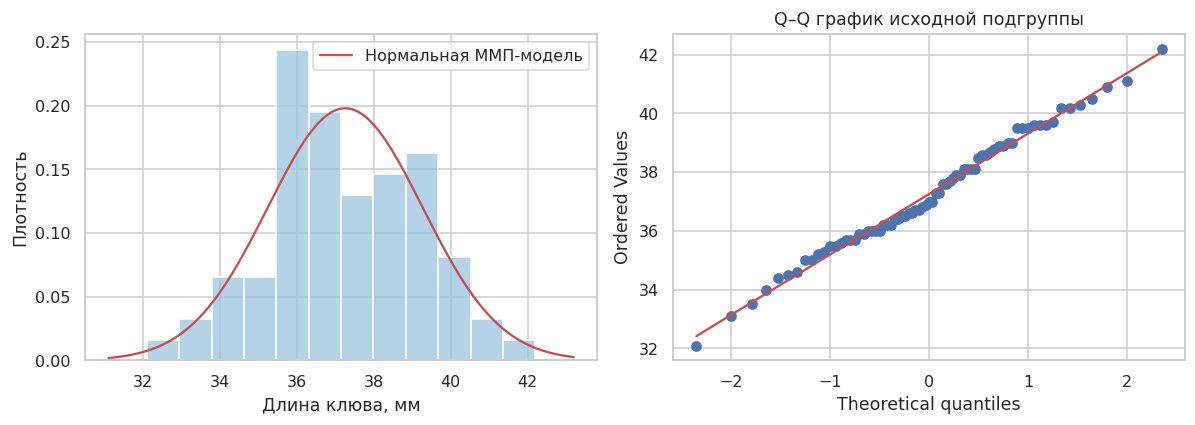

In [6]:
group = df.loc[(df['species']=='Adelie') & (df['sex']=='FEMALE')]
x = group['culmen_length_mm'].to_numpy(dtype=float)
n = len(x)

def log_likelihood(params, sample):
    mu, sigma = params
    sample = np.asarray(sample, dtype=float)
    if sigma <= 0 or not np.isfinite(sigma):
        return -np.inf
    return (-sample.size / 2 * np.log(2*np.pi) - sample.size*np.log(sigma)
            - np.sum((sample-mu)**2)/(2*sigma**2))

def nll_gradient(params, sample):
    mu, sigma = params
    return np.array([np.sum(mu-sample)/sigma**2,
                     len(sample)/sigma-np.sum((sample-mu)**2)/sigma**3])

initial = [float(np.median(x)+1), float(np.std(x, ddof=1)*1.4)]
opt = minimize(lambda p: -log_likelihood(p, x), initial,
               jac=lambda p: nll_gradient(p, x), method='L-BFGS-B',
               bounds=[(None,None),(1e-8,None)],
               options={'ftol': 1e-14, 'gtol': 1e-9, 'maxiter': 10000})
if not opt.success:
    raise RuntimeError(opt.message)
mu_num, sigma_num = opt.x
mu0, sigma0 = float(x.mean()), float(x.std(ddof=0))
W, pvalue = stats.shapiro(x)
print('n =', n, '| начальная точка =', initial)
print('Оптимизация:', opt.message, '| итераций:', opt.nit)
print('ММП численно:', opt.x, '| log L =', log_likelihood(opt.x,x))
print(f'Шапиро–Уилк: W={W:.6f}; p={pvalue:.6f}; alpha=0.05')
print('Асимметрия:', stats.skew(x,bias=False), 'Эксцесс:', stats.kurtosis(x,bias=False))
print('Разность с формулами:', opt.x-np.array([mu0,sigma0]))
assert np.allclose(opt.x, [mu0,sigma0], rtol=1e-7, atol=1e-7)
fig, axes=plt.subplots(1,2,figsize=(11,4))
sns.histplot(x=x, bins=12, stat='density', ax=axes[0], color='#9cc5df')
grid=np.linspace(x.min()-1, x.max()+1, 400)
axes[0].plot(grid, stats.norm.pdf(grid,mu_num,sigma_num), 'r-', label='Нормальная ММП-модель')
axes[0].set(xlabel='Длина клюва, мм', ylabel='Плотность'); axes[0].legend()
stats.probplot(x, dist='norm', plot=axes[1]); axes[1].set_title('Q–Q график исходной подгруппы')
plt.tight_layout(); savefig('05_normal_fit')

## 5 Вторая модель без scipy.optimize и scikit-learn
Аналитические функции ниже используют только стандартный модуль `math`, циклы и суммы. Они не вызывают оптимизатор, `numpy.mean`, `numpy.std` или готовый `.fit`. Реализация также сохранена отдельно в `manual_mle.py`.

Для метода моментов $E[X]=\mu$ и $E[X^2]=\mu^2+\sigma^2$. Приравняв их $m_1=n^{-1}\sum x_i$ и $m_2=n^{-1}\sum x_i^2$, получаем $\hat\mu_{MM}=m_1$, $\hat\sigma^2_{MM}=m_2-m_1^2$. **Для нормальной модели метод моментов и ММП совпадают для любой непостоянной выборки**, даже если сами данные не нормальны. Ненормальность данных не делает эти две формулы разными.

Исправленная дисперсия $s^2=\sum(x_i-\bar x)^2/(n-1)$ несмещённа при независимой выборке с конечной дисперсией. Её корень $s$ в общем случае не является несмещённой оценкой σ.

In [7]:
import math

def normal_mle_manual(values):
    values = [float(v) for v in values]
    if len(values) < 2 or not all(math.isfinite(v) for v in values):
        raise ValueError('Нужны хотя бы два конечных наблюдения')
    mu = sum(values)/len(values)
    variance = sum((v-mu)**2 for v in values)/len(values)
    if variance <= 0:
        raise ValueError('Для постоянной выборки нет конечного ММП при sigma > 0')
    return mu, math.sqrt(variance)

def exponential_mle_manual(values):
    values = [float(v) for v in values]
    if not values or not all(math.isfinite(v) and v >= 0 for v in values):
        raise ValueError('Нужна непустая выборка конечных неотрицательных значений')
    total = sum(values)
    if total <= 0:
        raise ValueError('Для всех нулей нет конечного ММП интенсивности')
    return len(values)/total

In [8]:
mu_manual, sigma_manual = normal_mle_manual(x)
m1, m2 = sum(float(v) for v in x)/n, sum(float(v)**2 for v in x)/n
mu_mm, sigma_mm = m1, math.sqrt(m2-m1*m1)
mu_fit, sigma_fit = stats.norm.fit(x)
comparison = pd.DataFrame([
    ['ММП численно',mu_num,sigma_num,sigma_num**2],
    ['ММП вручную',mu_manual,sigma_manual,sigma_manual**2],
    ['Метод моментов',mu_mm,sigma_mm,sigma_mm**2],
    ['scipy.stats.norm.fit',mu_fit,sigma_fit,sigma_fit**2],
    ['Выборочные ddof=0',x.mean(),x.std(ddof=0),x.var(ddof=0)],
    ['Исправленные ddof=1',x.mean(),x.std(ddof=1),x.var(ddof=1)]
],columns=['method','mu','sigma','variance']).set_index('method')
table(comparison,'normal_comparison')
assert np.allclose([mu_manual,sigma_manual],[mu_mm,sigma_mm],atol=1e-10)
assert np.allclose([mu_fit,sigma_fit],[mu_manual,sigma_manual],atol=1e-10)

,mu,sigma,variance
method,,,
ММП численно,37.257534,2.014939,4.059977
ММП вручную,37.257534,2.014939,4.059977
Метод моментов,37.257534,2.014939,4.059977
scipy.stats.norm.fit,37.257534,2.014939,4.059977
Выборочные ddof=0,37.257534,2.014939,4.059977
Исправленные ddof=1,37.257534,2.028883,4.116366


## 6 Монте Карло при исходном объёме выборки
Проводим ровно **500 независимых повторений**, в каждом генерируем **n = 73** нормальных наблюдения. Истинными параметрами *симуляционной модели* считаем аналитические ММП по реальным данным. Это не утверждение, что истинные параметры природной популяции известны.

Для каждого повтора используем аналитическое ММП, уже проверенное сравнением с оптимизатором. Вычисляем смещение, стандартное отклонение, MSE и стандартную ошибку среднего по Монте-Карло (MCSE = SD/√500).

Теоретические свойства при нормальной модели:
$$E[\hat\mu]=\mu,\quad \operatorname{Var}(\hat\mu)=\sigma^2/n,$$
$$E[\hat\sigma^2]=(n-1)\sigma^2/n,\quad \operatorname{Var}(\hat\sigma^2)=2(n-1)\sigma^4/n^2.$$
Для σ вводим $c_n=\sqrt{2/n}\,\Gamma(n/2)/\Gamma((n-1)/2)$. Тогда
$$E[\hat\sigma]=c_n\sigma,\quad \operatorname{Var}(\hat\sigma)=\sigma^2[(n-1)/n-c_n^2].$$
При конечном n обе ММП-оценки масштаба смещены вниз. При n→∞ смещение исчезает. Среднее нормально распределено **точно** при любом n; оценки σ и σ² нормальны лишь асимптотически.

,true,mean,bias,theory_bias,SD,theory_SD,MSE,MCSE
parameter,,,,,,,,
mu,37.257534,37.261857,0.004323,0.000000,0.221459,0.235831,0.048965,0.009904
sigma,2.014939,2.005934,-0.009005,-0.020784,0.164477,0.166466,0.027080,0.007356
sigma_squared,4.059977,4.050769,-0.009209,-0.055616,0.670609,0.667394,0.448902,0.029991


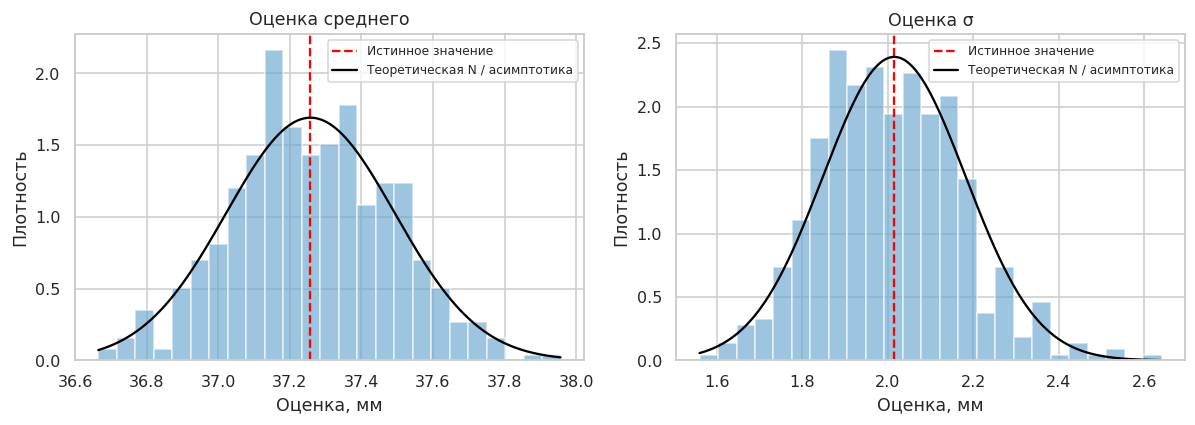

In [9]:
def c_n(size):
    return math.sqrt(2/size)*math.exp(math.lgamma(size/2)-math.lgamma((size-1)/2))

streams = np.random.SeedSequence(SEED).spawn(3)
rng_main, rng_consistency, rng_exp = [np.random.default_rng(s) for s in streams]
samples = rng_main.normal(mu0,sigma0,size=(B,n))
# Применяем вручную реализованную функцию к каждой выборке.
estimates = np.array([normal_mle_manual(row) for row in samples])
mu_est, sigma_est = estimates.T
var_est = sigma_est**2
cn = c_n(n)
theory_mean = [mu0,cn*sigma0,(n-1)/n*sigma0**2]
theory_sd = [sigma0/math.sqrt(n),sigma0*math.sqrt((n-1)/n-cn**2),
             sigma0**2*math.sqrt(2*(n-1))/n]
mc_rows=[]
for name,vals,true,tm,ts in zip(['mu','sigma','sigma_squared'],
    [mu_est,sigma_est,var_est],[mu0,sigma0,sigma0**2],theory_mean,theory_sd):
    mc_rows.append([name,true,vals.mean(),vals.mean()-true,tm-true,
                   vals.std(ddof=1),ts,np.mean((vals-true)**2),vals.std(ddof=1)/math.sqrt(B)])
mc=pd.DataFrame(mc_rows,columns=['parameter','true','mean','bias','theory_bias',
                                'SD','theory_SD','MSE','MCSE']).set_index('parameter')
table(mc,'monte_carlo_500')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,vals,true,sd,title in zip(axes,[mu_est,sigma_est],[mu0,sigma0],
    [sigma0/np.sqrt(n),sigma0/np.sqrt(2*n)],['Оценка среднего','Оценка σ']):
    ax.hist(vals,bins=25,density=True,alpha=.65,color='#6aa6cf')
    ax.axvline(true,color='red',ls='--',label='Истинное значение')
    grid=np.linspace(vals.min(),vals.max(),300)
    ax.plot(grid,stats.norm.pdf(grid,true,sd),color='black',label='Теоретическая N / асимптотика')
    ax.set(title=title,xlabel='Оценка, мм',ylabel='Плотность'); ax.legend(fontsize=8)
plt.tight_layout();savefig('06_mc_histograms')

## 7 Состоятельность и асимптотическая нормальность
Для каждого n из {10, 20, 30, 50, 73, 100, 200, 500} проводим по 500 новых повторений. Точки отражают конечное число симуляций, поэтому небольшие случайные отклонения от теоретической кривой ожидаемы. Исследование показывает поведение оценок, но математическое доказательство состоятельности опирается на закон больших чисел: $\bar X\to_p\mu$ и $n^{-1}\sum X_i^2-\bar X^2\to_p\sigma^2$. Непрерывность корня даёт состоятельность оценки σ.

Информация Фишера для одного наблюдения в параметрах (μ, σ):
$$I_1(\mu,\sigma)=\begin{pmatrix}1/\sigma^2&0\\0&2/\sigma^2\end{pmatrix}.$$
Следовательно, асимптотические дисперсии равны σ²/n и σ²/(2n). Для параметризации (μ, σ²) нижний диагональный элемент информации равен 1/(2σ⁴), а асимптотическая дисперсия оценки σ² равна 2σ⁴/n.

Стандартизованные оценки $Z_\mu=\sqrt n(\hat\mu-\mu)/\sigma$ и $Z_\sigma=\sqrt{2n}(\hat\sigma-\sigma)/\sigma$ сравниваются с N(0,1), включая Q–Q графики. Асимптотическая эффективность относится к корректно заданной регулярной модели; безусловную конечновыборочную эффективность смещённой оценки σ утверждать нельзя.

,SD_mu,theory_SD_mu,SD_sigma,exact_SD_sigma,asympt_SD_sigma,bias_mu,bias_sigma,MSE_mu,MSE_sigma
n,,,,,,,,,
10,0.646285,0.637180,0.467154,0.443930,0.450554,0.008990,-0.173803,0.416930,0.248004
20,0.453838,0.450554,0.313640,0.316433,0.318590,-0.021793,-0.075138,0.206032,0.103819
30,0.352073,0.367876,0.244669,0.258985,0.260127,-0.018919,-0.062314,0.124066,0.063626
50,0.287420,0.284955,0.189517,0.200974,0.201494,0.000511,-0.029676,0.082445,0.036726
73,0.239987,0.235831,0.155169,0.166466,0.166758,0.012814,-0.016304,0.057643,0.024295
100,0.200996,0.201494,0.147632,0.142297,0.142478,0.000246,-0.022021,0.040319,0.022237
200,0.143303,0.142478,0.097398,0.100683,0.100747,-0.001835,-0.007462,0.020498,0.009523
500,0.091390,0.090111,0.065102,0.063702,0.063718,-0.003349,-0.006583,0.008347,0.004273


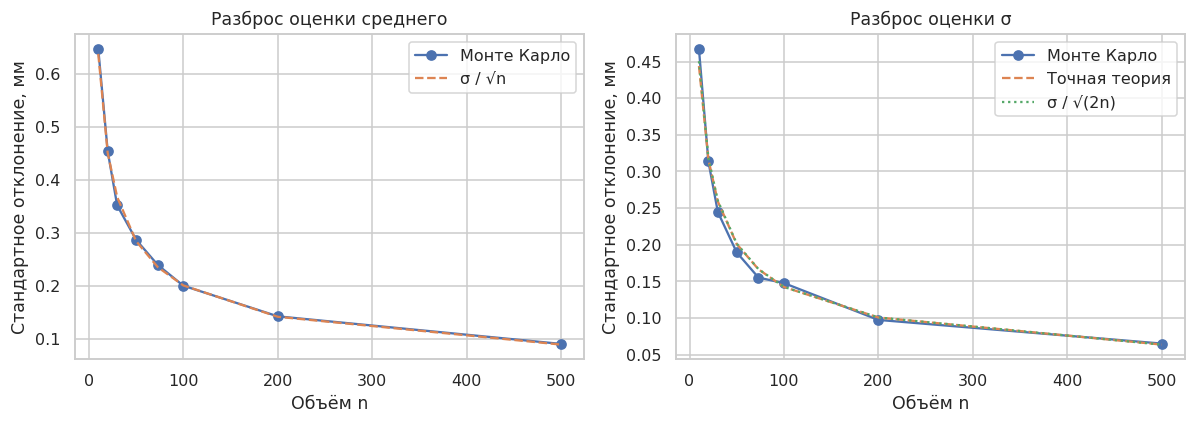

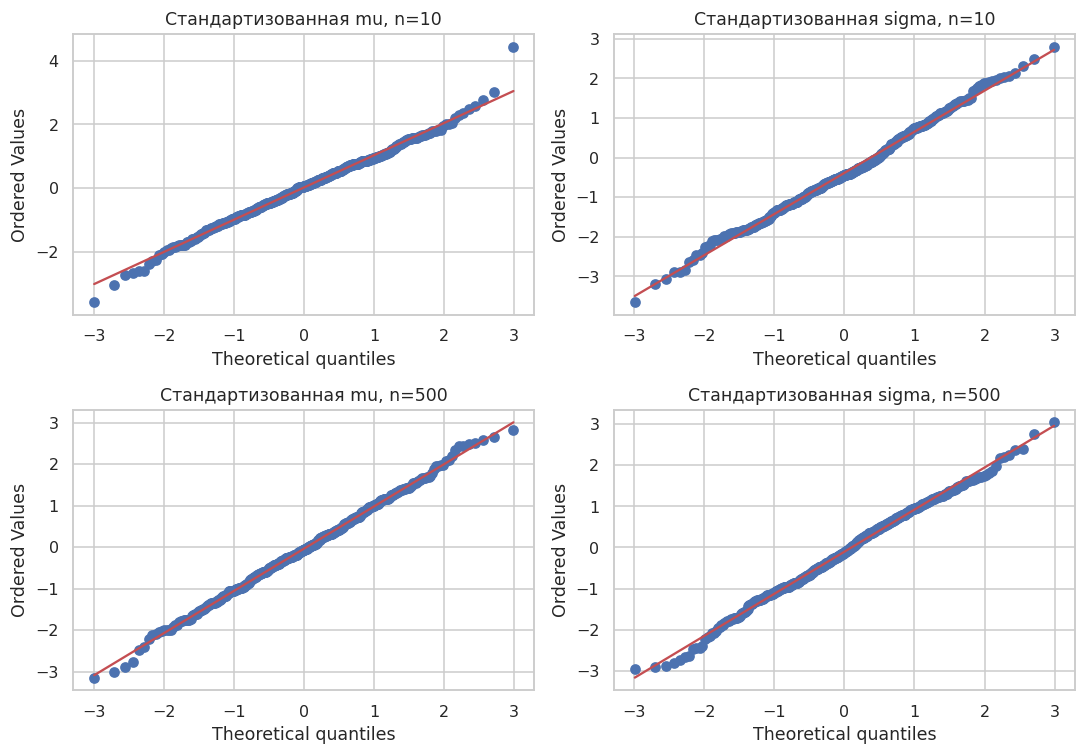

,n,parameter,mean_Z,SD_Z,skew,excess
0,10,mu,0.014109,1.014290,-0.008913,0.772097
1,10,sigma,-0.385755,1.036844,0.161276,0.018502
2,500,mu,-0.037161,1.014201,0.002155,0.026205
3,500,sigma,-0.103319,1.021722,-0.099011,-0.085712


In [10]:
sizes=[10,20,30,50,n,100,200,500]
cons_rows=[]; standardized={}
for size in sizes:
    sims=rng_consistency.normal(mu0,sigma0,size=(B,size))
    est=np.array([normal_mle_manual(row) for row in sims])
    cm=c_n(size)
    cons_rows.append([size,est[:,0].std(ddof=1),sigma0/math.sqrt(size),
      est[:,1].std(ddof=1),sigma0*math.sqrt((size-1)/size-cm**2),
      sigma0/math.sqrt(2*size),est[:,0].mean()-mu0,est[:,1].mean()-sigma0,
      np.mean((est[:,0]-mu0)**2),np.mean((est[:,1]-sigma0)**2)])
    if size in [10,500]:
        standardized[size]=(np.sqrt(size)*(est[:,0]-mu0)/sigma0,
                            np.sqrt(2*size)*(est[:,1]-sigma0)/sigma0)
cons=pd.DataFrame(cons_rows,columns=['n','SD_mu','theory_SD_mu','SD_sigma',
    'exact_SD_sigma','asympt_SD_sigma','bias_mu','bias_sigma','MSE_mu','MSE_sigma']).set_index('n')
table(cons,'consistency')
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(cons.index,cons.SD_mu,'o-',label='Монте Карло')
axes[0].plot(cons.index,cons.theory_SD_mu,'--',label='σ / √n')
axes[1].plot(cons.index,cons.SD_sigma,'o-',label='Монте Карло')
axes[1].plot(cons.index,cons.exact_SD_sigma,'--',label='Точная теория')
axes[1].plot(cons.index,cons.asympt_SD_sigma,':',label='σ / √(2n)')
for ax,title in zip(axes,['Разброс оценки среднего','Разброс оценки σ']):
    ax.set(title=title,xlabel='Объём n',ylabel='Стандартное отклонение, мм');ax.legend()
plt.tight_layout();savefig('07_consistency')
fig,axes=plt.subplots(2,2,figsize=(10,7))
normality_rows=[]
for row,size in enumerate([10,500]):
    for j,name in enumerate(['mu','sigma']):
        z=standardized[size][j]
        stats.probplot(z,dist='norm',plot=axes[row,j])
        axes[row,j].set_title(f'Стандартизованная {name}, n={size}')
        normality_rows.append([size,name,z.mean(),z.std(ddof=1),
                              stats.skew(z,bias=False),stats.kurtosis(z,bias=False)])
plt.tight_layout();savefig('08_asymptotic_qq')
table(pd.DataFrame(normality_rows,columns=['n','parameter','mean_Z','SD_Z','skew','excess']),
      'asymptotic_diagnostics')

## 8 Другое распределение и ручное ММП
Дополнительная модель — экспоненциальное распределение с **фиксированным сдвигом 0** и интенсивностью λ>0. Не приписываем эту модель длине клюва: её плотность максимальна при нуле и монотонно убывает, что не соответствует изучаемому признаку. Для проверки алгоритма используем отдельную синтетическую выборку размера 73 из Exp(λ₀), где λ₀ = 0,4. Эти данные явно отделены от реального датасета.
$$f(y;\lambda)=\lambda e^{-\lambda y},\quad y\ge0,$$
$$\ell(\lambda)=n\log\lambda-\lambda\sum y_i,\quad
\ell'(\lambda)=n/\lambda-\sum y_i=0.$$
$$\hat\lambda=n/\sum y_i=1/\bar y,\qquad \ell''(\lambda)=-n/\lambda^2<0.$$
Это глобальный максимум при положительной сумме наблюдений. Метод моментов здесь также даёт 1/ȳ. Для численного решения используем θ=log λ, что обеспечивает положительность λ. При сравнении со `scipy.stats.expon.fit` фиксируем `floc=0`; свободный сдвиг означал бы другую модель.

,lambda
Истинный параметр,0.400000
ММП вручную,0.403027
ММП численно,0.403027
scipy expon.fit floc=0,0.403027
Метод моментов,0.403027


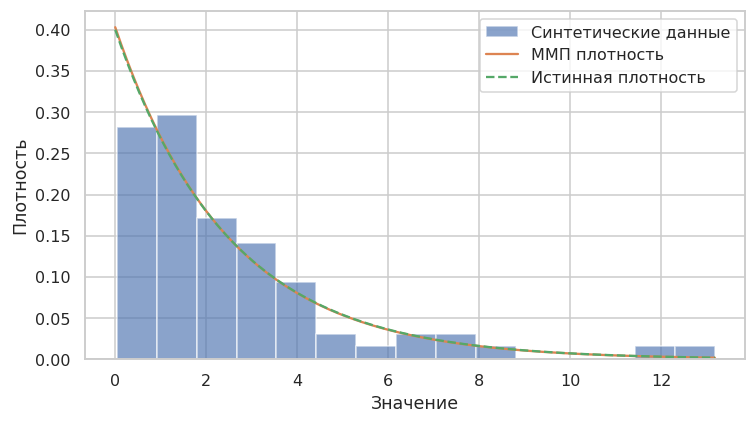

In [11]:
lambda_true=0.4
y=rng_exp.exponential(scale=1/lambda_true,size=n)
lambda_manual=exponential_mle_manual(y)
def exp_nll_theta(theta,sample):
    rate=np.exp(theta[0])
    return -len(sample)*theta[0]+rate*np.sum(sample)
exp_opt=minimize(exp_nll_theta,[math.log(.8)],args=(y,),method='BFGS',
    jac=lambda theta,sample: np.array([-len(sample)+np.exp(theta[0])*np.sum(sample)]),
    options={'gtol':1e-8})
if not exp_opt.success: raise RuntimeError(exp_opt.message)
lambda_num=float(np.exp(exp_opt.x[0]))
_, exp_scale=stats.expon.fit(y,floc=0)
exp_comparison=pd.DataFrame({'lambda':[lambda_true,lambda_manual,lambda_num,1/exp_scale,1/y.mean()]},
 index=['Истинный параметр','ММП вручную','ММП численно','scipy expon.fit floc=0','Метод моментов'])
table(exp_comparison,'exponential_comparison')
assert np.isclose(lambda_manual,lambda_num,rtol=1e-7)
assert np.isclose(lambda_manual,1/exp_scale,rtol=1e-12)
plt.figure(figsize=(7,4))
plt.hist(y,bins=15,density=True,alpha=.65,label='Синтетические данные')
grid=np.linspace(0,y.max(),300)
plt.plot(grid,lambda_manual*np.exp(-lambda_manual*grid),label='ММП плотность')
plt.plot(grid,lambda_true*np.exp(-lambda_true*grid),'--',label='Истинная плотность')
plt.xlabel('Значение');plt.ylabel('Плотность');plt.legend();plt.tight_layout();savefig('09_exponential')

## 9 Выводы по результатам расчётов
1. После очистки осталось **342** строк из 344; удалены две строки с отсутствующими измерениями. Полных дубликатов — 0. Неизвестный пол остаётся у 9 записей и не мешает общему EDA. По правилу 1,5·IQR в объединённой выборке число выбросов по каждому из четырёх признаков равно нулю. Это не исключает аномалий внутри отдельных групп.
2. Гистограммы показывают смесь видовых распределений. Длина ласта и масса имеют положительную асимметрию; глубина клюва образует видовые группы. Сильная связь массы и длины ласта: **r = 0.871202**. В общей выборке длина и глубина клюва коррелируют отрицательно (**r = -0.235053**), тогда как внутри каждого вида знак положительный. Агрегирование групп меняет интерпретацию связи; корреляция не доказывает причинность.
3. Максимальный VIF = **5.930** у длины ласта. Совместное использование сильно связанных размеров в линейной модели требует контроля мультиколлинеарности. Парный коэффициент сам по себе недостаточен для окончательного диагноза.
4. Для длины клюва самок Adelie: n = **73**, μ̂ = **37.257534 мм**, σ̂ = **2.014939 мм**, σ̂² = **4.059977 мм²**. Исправленное стандартное отклонение s = **2.028883 мм**. Тест Шапиро–Уилка: W = **0.991170**, p = **0.895192**. При α = 0,05 оснований отвергать нормальность нет; это не доказательство точной нормальности. Q–Q график согласуется с приближённой нормальной моделью.
5. Численная оптимизация, ручное ММП, метод моментов и `norm.fit` совпали в пределах численной погрешности. Нельзя объявить один из этих двух методов более точным для этой модели: они дают одинаковые оценки на одной выборке; истинные параметры реальной популяции неизвестны.
6. При 500 повторах исходного объёма n = 73 среднее μ̂ равно **37.261857**, среднее σ̂ — **2.005934**. Эмпирические смещения равны **0.004323** и **-0.009005**. Теоретическое смещение μ̂ равно нулю, σ̂ — **-0.020784**. MCSE из таблицы показывает масштаб случайной погрешности этих средних; 500 повторов не доказывают несмещённость и могут плохо различать малое смещение σ̂.
7. При увеличении n от 10 до 500 SD оценки среднего уменьшилось с **0.646285** до **0.091390**, а SD оценки σ — с **0.467154** до **0.065102**. Снижаются и MSE; результат согласуется с состоятельностью и скоростью убывания разброса 1/√n. Стандартизованные распределения и Q–Q графики согласуются с асимптотической нормальностью, особенно при n = 500.
8. Для отдельной экспоненциальной модели ручная и численная оценки интенсивности равны **0.403027** при заданном λ₀ = 0,4. Отличие от истинного параметра — выборочная ошибка, а не расхождение алгоритмов.

**Практические рекомендации.** Для этой подгруппы допустимо использовать нормальную модель как приближение, предварительно проверив графики, пропуски и предположение независимости. Для расчётов нормального ММП предпочтительны аналитические формулы: они быстрее и не требуют подбора начальной точки. Если нужна несмещённая оценка дисперсии, использовать ddof=1; это не делает её квадратный корень несмещённым. В нормальной модели несмещённую оценку σ можно получить как σ̂/cₙ. Не переносить оценки этой подгруппы на все виды и оба пола. Не удалять наблюдения только ради улучшения p-значения. При выраженном отклонении от нормальности изменить модель и заново вывести ММП; обычные формулы информации Фишера для корректной нормальной модели тогда нельзя применять без проверки.

## 10 Источники и проверка полноты
1. Задание «Лаб 2 соив.docx», раздел 4 — состав работы.
2. Kaggle, Palmer Archipelago (Antarctica) penguin data — ссылка приведена в начале.
3. Gorman et al. (2014), первичная публикация и репозиторий — ссылки приведены в начале.
4. SciPy `minimize`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html
5. SciPy `shapiro`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html
6. NumPy `std`: https://numpy.org/doc/stable/reference/generated/numpy.std.html

Выполнены очистка данных; гистограммы и boxplot всех количественных признаков; корреляционная матрица и pairplot; статистики; численное и ручное ММП нормального распределения; сравнение с методом моментов и библиотекой; 500 повторов исходного объёма; исследование n от 10 до 500; проверка асимптотики; аналитическое и численное решение для другого распределения. Версии реально использованных библиотек напечатаны в первой кодовой ячейке. Выводы сохранены вместе с исполненными ячейками и изображениями.